In [1]:
from photutils.detection import DAOStarFinder
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile

from matplotlib import pyplot as plt
import numpy as np

#import ccdproc

from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

In [2]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='gray_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)
    
def add_stars(xstars,ystars,radius=20,color='r',ax=None):
    ''' this will add circles at the location of xstars,ystars '''
    if ax is None:
        ax = plt.gca()
    allcircles=[]
    #The zip function takes iterables (e.g. lists or arrays) and groups them into tuples that contain 
    #matched pairs of each input, e.g [(x,y)]
    for x,y in zip(xstars,ystars):
        c = plt.Circle((x,y),radius,color=color,fill=False)
        #allcircles.append(c)
        ax.add_artist(c)

Text(0.5, 1.0, 'M5 G-band image')

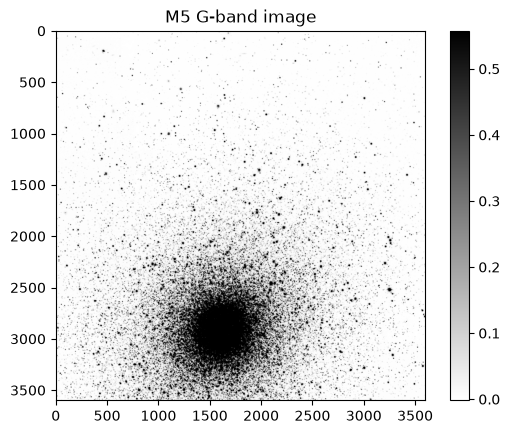

In [3]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('M5 G-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M5 G-band image")

**Why:** We plotted the G-band image to see the stars in M5 and check the image before measuring their brightness.

**What we found:** The image contains many stars, especially near the center of the cluster. Some stars are very close together, which can make their brightness harder to measure.

Text(0.5, 1.0, 'M5 R-band image')

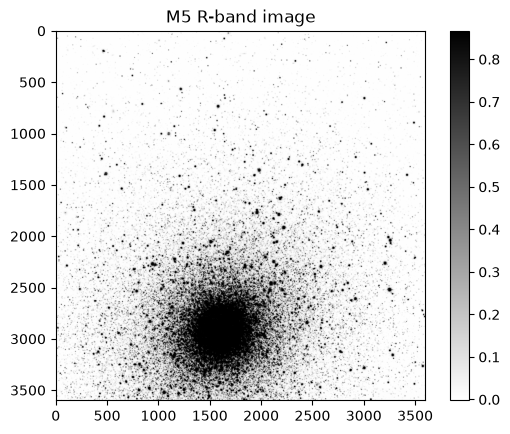

In [4]:
#make the figure
plt.figure()

#read in the data and header
data,header = fits.getdata('M5 R-band image.fits', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data)
plt.title("M5 R-band image")

**Why:** We plotted the R-band image to compare it with the G-band image and see how the stars appear in a different filter.

**What we found:** Many sources are visible in both images. Their brightness can change between the filters, which allows us to calculate their colors.

In [5]:
from astropy.io import fits
from photutils.psf import fit_fwhm

def calc_fwhm(imagefilename, xyposlist):
    '''
    This function takes as input an image file name and a list of star pixel coordinates 
    and prints the FWHM for each star.  

    Stars should be bright, unsaturated, and isolated.

    INPUTS: 
    imagefilename: a string containing the image file name

    xyposlist: a list of x and y coordinates of the form [(x1,y1), (x2,y2)]
    This can contain an arbitrary number of stars.

    OUTPUT:
    fwhmlist: a list of FWHM
    '''
    image = fits.getdata(imagefilename)
    
    #use the photutils.psf.fit_fwhm function to fit a 2D PSF to the stars.
    fwhm = fit_fwhm(
        image,
        xypos=xyposlist,
        fwhm=4.0,        # initial guess, pixels
        fit_shape=21
    )
    print(f'The FWHM of the stars in {imagefilename} in pixels are {fwhm}')
    return(fwhm)

In [6]:
# Calculate FWHM for M5 G-band

M5Gstars = [(2310,838),(2546,999),(2320,1047),(2512,1177),(1906,1277)]

M5G_fwhm = calc_fwhm('M5 G-band image.fits', M5Gstars)

print("G-band FWHM:", M5G_fwhm)
print("Mean G-band FWHM:", np.mean(M5G_fwhm))
print("Median G-band FWHM:", np.median(M5G_fwhm))

The FWHM of the stars in M5 G-band image.fits in pixels are [5.64781659 5.60396522 5.85335296 5.8689761  6.09399896]
G-band FWHM: [5.64781659 5.60396522 5.85335296 5.8689761  6.09399896]
Mean G-band FWHM: 5.8136219658776165
Median G-band FWHM: 5.853352961264046


In [7]:
#read in the G-band image
M5data_G, M5header_G = fits.getdata('M5 G-band image.fits',header=True)

In [8]:
# estimate the background counts in the image by computing the 
# mean and median excluding all pixels greater than 3-sigma above the mean
M5mean_G, M5median_G, M5std_G = sigma_clipped_stats(M5data_G, sigma=3.0)

Text(0, 0.5, 'Y (pixels)')

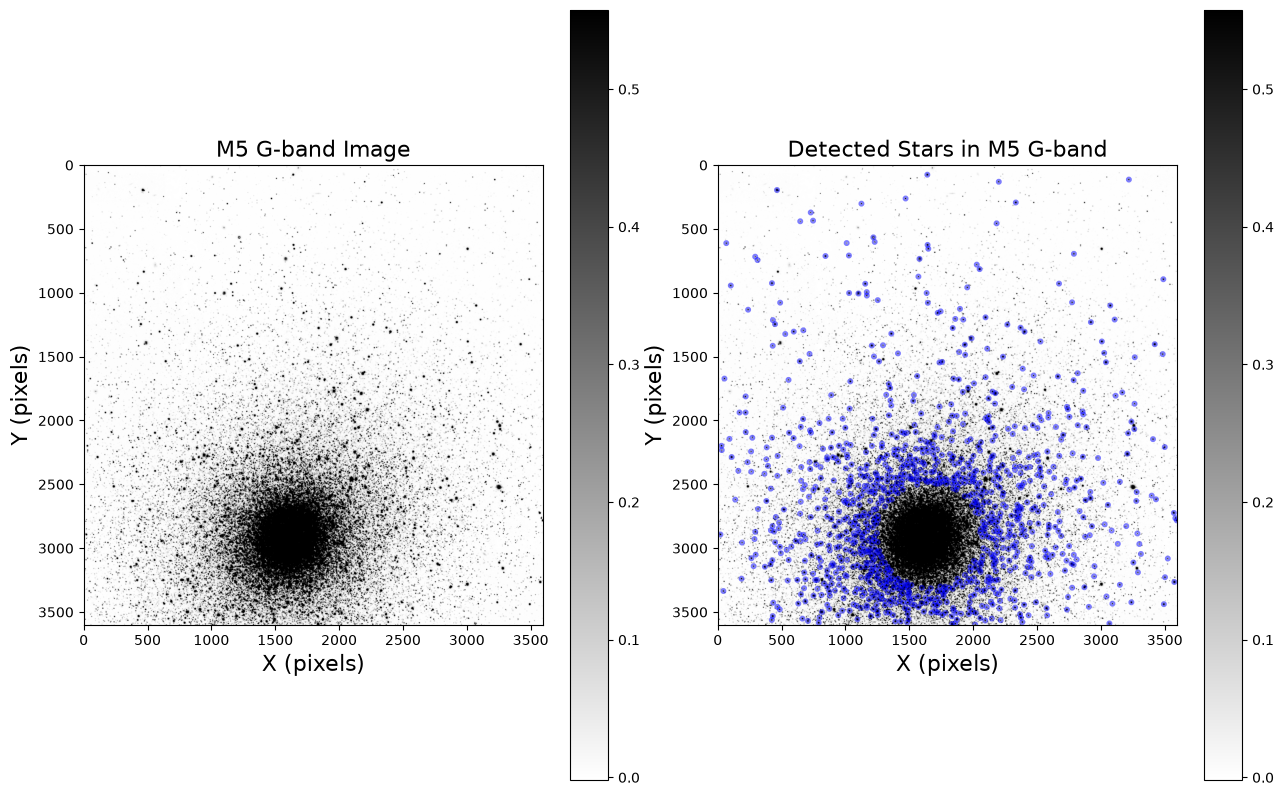

In [39]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
# update with the FWHM that you measured using fit_fwhm
#you will need to update the threshold number based on plots you make in the next cell.
daofind = DAOStarFinder(fwhm=5.81, threshold=150.*M5std_G)

# detect sources, using the image - median, which subtracts the sky level from image, 
# assuming a sky that is constant across the iamge
M5sources_G = daofind(M5data_G - M5median_G)

# convert pixel locations of images to ra and dec using the image header
wcs_G = WCS(M5header_G)
M5ra_G,M5dec_G = wcs_G.wcs_pix2world(M5sources_G['x_centroid'],M5sources_G['y_centroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
#plots G-band image
plt.figure(figsize=(15,10))
#select the left plot
plt.subplot(1,2,1)
imdisplay(M5data_G)

plt.title('M5 G-band Image', fontsize=16)
plt.xlabel('X (pixels)', fontsize=16)
plt.ylabel('Y (pixels)', fontsize=16)

#plot B-band image with the positions of the sources overlaid
#select the right plot
plt.subplot(1,2,2)

# Only detect stars on outskirts
# exclude stars outside a certain radius in pixels
r_excluded = 400
x_center = 1650
y_center = 2900

# distance of detected stars from the center
dist_from_center = np.sqrt( (M5sources_G['x_centroid'] - x_center)**2 + (M5sources_G['y_centroid'] - y_center)**2 )
# filter out stars so only stars outside the radius are kept
M5Gfiltered_sources = M5sources_G[dist_from_center > r_excluded]

#Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
#The transpose command puts the images into the correct format
positions = np.transpose((M5Gfiltered_sources['x_centroid'], M5Gfiltered_sources['y_centroid']))
#creates a set of circular apertues with r=15 pixels
apertures = CircularAperture(positions, r=15.)
imdisplay(M5data_G)
#plot the apertures.  the ';' at the end suppresses some messy output
apertures.plot(color='blue', lw=1.5, alpha=0.5);

plt.title('Detected Stars in M5 G-band', fontsize=16)
plt.xlabel('X (pixels)', fontsize=16)
plt.ylabel('Y (pixels)', fontsize=16)

**Why:** We plotted the detected stars to check if the program was finding sources in the correct positions. We excluded the central 400-pixel radius because the stars are very crowded in that region.

**What we found:** The detected sources are spread across the outer regions of M5. Excluding the center helps reduce the problem of overlapping stars, although some sources may still be close together.

Text(0.5, 1.0, 'M5 G-band')

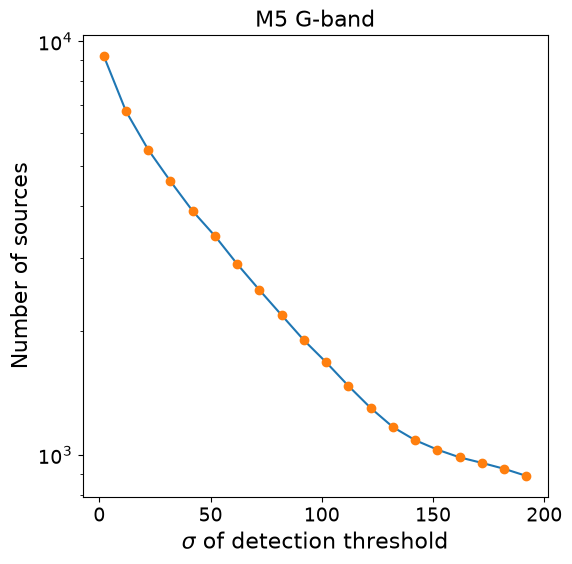

In [38]:
#This makes a plot of the number of sources for different detection thresholds for the G-band
#set up an array of thresholds
thresharr = np.arange(2.,200.,10)

#initialize an array that will hold the number of sources that are detected at each threshold
nsources_G = np.zeros(len(thresharr))

#loop through the thresholds to find how many sources are detected at each threshold
#************
#put in the appropriate FWHM you computed for this image earlier.
for ithresh,thresh in enumerate(thresharr):
    daofind = DAOStarFinder(fwhm=5.81, threshold=thresh*M5std_G)
    M5sources_Gtmp = daofind(M5data_G - M5median_G)
    # use filtered sources
    if M5sources_Gtmp is not None:
        dist_from_center = np.sqrt( (M5sources_Gtmp['x_centroid'] - x_center)**2 + (M5sources_Gtmp['y_centroid'] - y_center)**2 )
        M5sources_Gtmp = M5sources_Gtmp[dist_from_center > r_excluded]
        nsources_G[ithresh]=len(M5sources_Gtmp)
    else:
        nsources_G[ithresh]=0

#plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_G)
ax.plot(thresharr,nsources_G, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=16)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=16)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('M5 G-band', fontsize=16)

**Why:** We tested different detection thresholds to see how they change the number of sources found in the G-band image.

**What we found:** Lower thresholds detect more sources, while higher thresholds detect fewer sources. A higher threshold helps reduce noise detections, but some faint stars may be missed.

In [11]:
# Calculate FWHM for M5 R-band

M5Rstars = [(2322,1044),(2545,1001),(2673,928),(2776,1075),(2652,1309)]

M5R_fwhm = calc_fwhm('M5 R-band image.fits', M5Rstars)

print("R-band FWHM:", M5G_fwhm)
print("Mean R-band FWHM:", np.mean(M5R_fwhm))
print("Median R-band FWHM:", np.median(M5R_fwhm))

The FWHM of the stars in M5 R-band image.fits in pixels are [6.3380286  6.34293169 6.41538174 6.32961303 6.93935086]
R-band FWHM: [5.64781659 5.60396522 5.85335296 5.8689761  6.09399896]
Mean R-band FWHM: 6.473061183703784
Median R-band FWHM: 6.342931694938983


In [12]:
#read in the R-band image
M5data_R, M5header_R = fits.getdata('M5 R-band image.fits',header=True)

In [14]:
# estimate the background counts in the image by computing the 
# mean and median excluding all pixels greater than 3-sigma above the mean
M5mean_R, M5median_R, M5std_R = sigma_clipped_stats(M5data_R, sigma=3.0)

Text(0, 0.5, 'Y (pixels)')

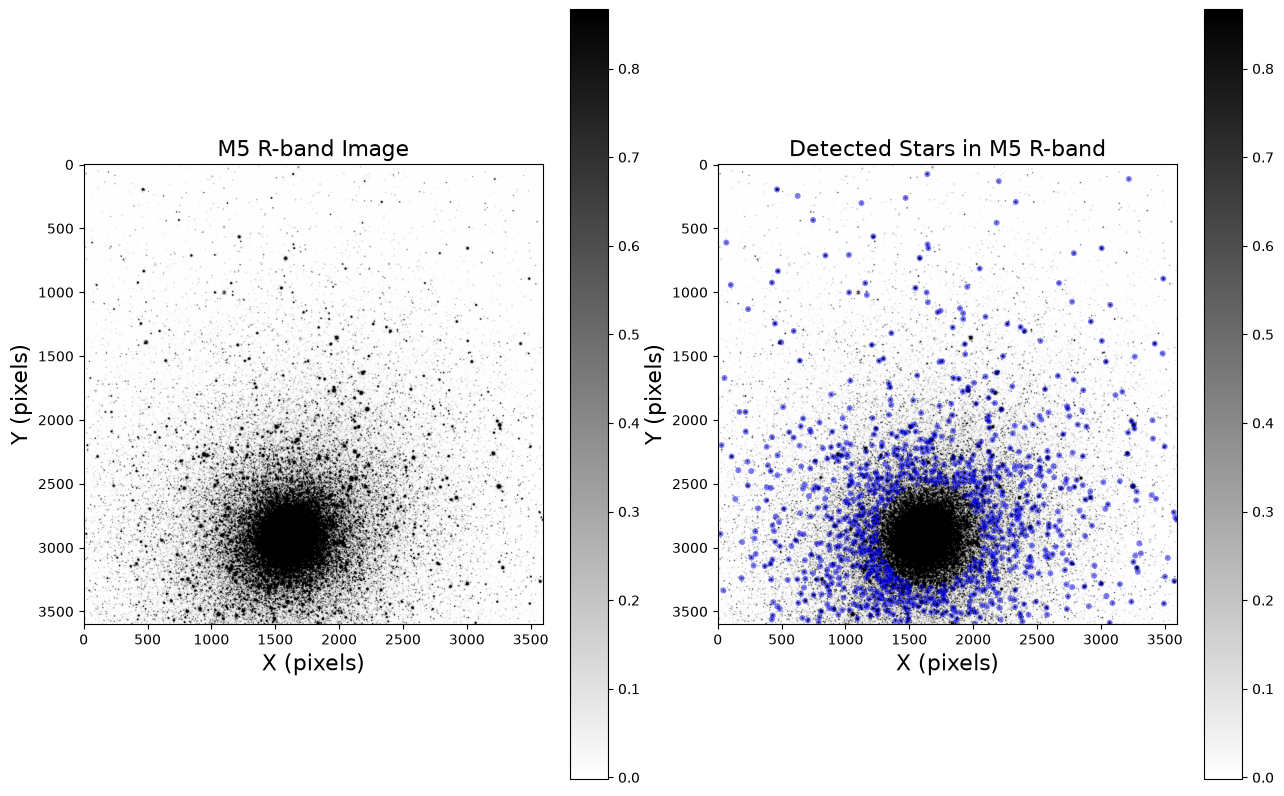

In [37]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
# update with the FWHM that you measured using fit_fwhm
#you will need to update the threshold number based on plots you make in the next cell.
daofind = DAOStarFinder(fwhm=6.47, threshold=150.*M5std_R)

# detect sources, using the image - median, which subtracts the sky level from image, 
# assuming a sky that is constant across the iamge
M5sources_R = daofind(M5data_R - M5median_R)

# convert pixel locations of images to ra and dec using the image header
wcs_R = WCS(M5header_R)
M5ra_R,M5dec_R = wcs_R.wcs_pix2world(M5sources_R['x_centroid'],M5sources_R['y_centroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
#plots G-band image
plt.figure(figsize=(15,10))
#select the left plot
plt.subplot(1,2,1)
imdisplay(M5data_R)

plt.title('M5 R-band Image', fontsize=16)
plt.xlabel('X (pixels)', fontsize=16)
plt.ylabel('Y (pixels)', fontsize=16)

#plot B-band image with the positions of the sources overlaid
#select the right plot
plt.subplot(1,2,2)

# Only detect stars on outskirts
# exclude stars outside a certain radius in pixels
r_excluded = 400
x_center = 1650
y_center = 2900

# distance of detected stars from the center
dist_from_center = np.sqrt( (M5sources_R['x_centroid'] - x_center)**2 + (M5sources_R['y_centroid'] - y_center)**2 )
# filter out stars so only stars outside the radius are kept
M5Rfiltered_sources = M5sources_R[dist_from_center > r_excluded]

#Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
#The transpose command puts the images into the correct format
positions = np.transpose((M5Rfiltered_sources['x_centroid'], M5Rfiltered_sources['y_centroid']))
#creates a set of circular apertues with r=15 pixels
apertures = CircularAperture(positions, r=15.)
imdisplay(M5data_R)
#plot the apertures.  the ';' at the end suppresses some messy output
apertures.plot(color='blue', lw=1.5, alpha=0.5);

plt.title('Detected Stars in M5 R-band', fontsize=16)
plt.xlabel('X (pixels)', fontsize=16)
plt.ylabel('Y (pixels)', fontsize=16)

**Why:** We plotted the detected R-band sources to check their positions and compare them with the G-band detections. We also excluded the crowded center of M5.

**What we found:** Many sources were detected in the outer regions. These positions can be compared with the G-band sources to find stars observed in both filters.

Text(0.5, 1.0, 'M5 R-band')

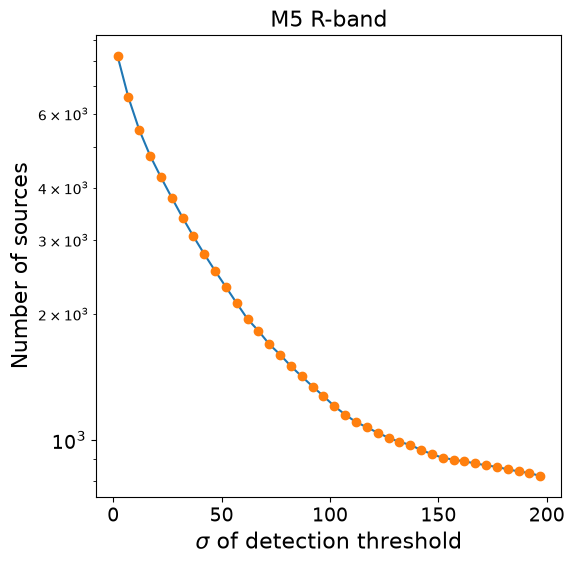

In [36]:
#This makes a plot of the number of sources for different detection thresholds for the G-band
#set up an array of thresholds
thresharr = np.arange(2.,200.,5)

#initialize an array that will hold the number of sources that are detected at each threshold
nsources_R = np.zeros(len(thresharr))

#loop through the thresholds to find how many sources are detected at each threshold
#************
#put in the appropriate FWHM you computed for this image earlier.
for ithresh,thresh in enumerate(thresharr):
    daofind = DAOStarFinder(fwhm=6.47, threshold=thresh*M5std_R)
    M5sources_Rtmp = daofind(M5data_R - M5median_R)
    # use filtered sources
    if M5sources_Rtmp is not None:
        dist_from_center = np.sqrt( (M5sources_Rtmp['x_centroid'] - x_center)**2 + (M5sources_Rtmp['y_centroid'] - y_center)**2 )
        M5sources_Rtmp = M5sources_Rtmp[dist_from_center > r_excluded]
        nsources_R[ithresh]=len(M5sources_Rtmp)
    else:
        nsources_R[ithresh]=0

#plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_R)
ax.plot(thresharr,nsources_R, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=16)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=16)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('M5 R-band', fontsize=16)

**Why:** We tested different thresholds in the R-band image to understand how the detection settings affect the results.

**What we found:** The number of detected sources decreases as the threshold increases. This shows that the threshold must be chosen carefully to avoid detecting too much noise or missing faint stars.

In [17]:
# Calculate background statistics for M5 G-band

M5mean_G, M5median_G,M5std_G =sigma_clipped_stats(M5data_G, sigma=3.0)

print("Mean:",M5mean_G)
print("Median:", M5median_G)
print("Standard deviation:",M5std_G)

Mean: 0.010361341
Median: 0.003136485
Standard deviation: 0.019552331


In [18]:
# Find stars in M5 G-band

M5daofind_G =DAOStarFinder(fwhm=5.81,threshold=150*M5std_G)

M5sources_G =M5daofind_G(M5data_G-M5median_G)

print("Number of detected stars:",len(M5Gfiltered_sources))
print(M5Gfiltered_sources[:10])

Number of detected stars: 1045
 id     x_centroid     ...         mag              daofind_mag     
--- ------------------ ... ------------------- ---------------------
  1 1641.1165278330197 ...  -6.956831845848503    -2.923304562296104
  2 3219.2897003940257 ...  -5.330992140327383    -1.262971344036656
  3 2200.6759350991033 ...  -5.470921056459954   -1.3702525163009986
  4 463.93079360365823 ...  -7.246032857690047    -2.629056051624395
  5 1470.8415621159666 ...  -5.524476220210075   -1.4966434074051105
  6 2333.7760421008747 ...  -5.868336137208131   -1.3880265154311284
  7  1125.035086642364 ... -4.9252176968590335   -0.8472452881144408
  8  728.0126296001171 ...  -4.198503780671397   -0.1657514535565678
  9  746.3437409559464 ...  -5.334979382889809    -1.420180203159768
 10  645.8222161725026 ...  -4.018135316423342 -0.016510746657043843


In [19]:
# Calculate background statistics for M5 R-band

M5mean_R, M5median_R, M5std_R = sigma_clipped_stats(M5data_R, sigma=3.0)

print("Mean:", M5mean_R)
print("Median:", M5median_R)
print("Standard deviation:", M5std_R)

Mean: 0.018974347
Median: 0.0050593317
Standard deviation: 0.0338163


In [51]:
# Find stars in M5 R-band

M5daofind_R = DAOStarFinder(fwhm=6.47,threshold=80*M5std_R)

M5sources_R = M5daofind_R(M5data_R - M5median_R)

print("Number of detected stars:", len(M5Rfiltered_sources))
print(M5Rfiltered_sources[:10])

Number of detected stars: 1132
 id     xcentroid          ycentroid      ...    mag         daofind_mag    
--- ------------------ ------------------ ... ---------- -------------------
  1   1641.12759148064  75.10183056499703 ... -7.0105557 -2.2961620656674175
  2  3219.260730842318  113.4901566134375 ... -6.2627406 -1.5081888368627907
  3 2200.6533313031346 130.37738282899613 ...  -6.085954 -1.3342598543513948
  4  463.8835943565586 195.05057840077475 ...  -8.017425  -2.869725849515341
  5  473.2157751359705  198.0457949188442 ... -5.8157372 -0.5801667283077004
  6  625.8518814474975 245.70126288710185 ... -4.8920374 -0.1854496109766021
  7 1470.7918687908511  261.6256079776332 ...   -6.42873  -1.693243719887819
  8 2333.9785880614522  292.7804043970433 ... -6.6340213 -1.5092236788511693
  9 1125.1212317160368 301.93915349284697 ...  -5.473371 -0.3344471650572128
 10  746.1905124331253  435.0644220389028 ... -6.4345875 -1.3547093187988266


In [20]:

from astropy.coordinates import SkyCoord
from astropy import units as u

#select stars outside the center of M5
x_center=1650
y_center = 2900
r_excluded= 400

#calculate distance from the center in G
distance_G = np.sqrt((M5sources_G['xcentroid'] - x_center)**2+(M5sources_G['ycentroid'] - y_center)**2)

# Calculate distance from the center in R
distance_R = np.sqrt((M5sources_R['xcentroid'] - x_center)**2 +(M5sources_R['ycentroid'] - y_center)**2)

# Keep stars outside the central region
M5Gfiltered_sources =M5sources_G[distance_G > r_excluded]
M5Rfiltered_sources =M5sources_R[distance_R > r_excluded]

#convert pixel coordinates to RA and DEC
M5wcs_G= WCS(M5header_G)
M5wcs_R= WCS(M5header_R)

M5ra_G, M5dec_G = M5wcs_G.all_pix2world(M5Gfiltered_sources['xcentroid'],M5Gfiltered_sources['ycentroid'], 0)

M5ra_R, M5dec_R= M5wcs_R.all_pix2world(M5Rfiltered_sources['xcentroid'],M5Rfiltered_sources['ycentroid'], 0)

print("G coordinates:", len(M5ra_G))
print("R coordinates:", len(M5ra_R))

#create sky coordinate catalogs
M5G_catalog=SkyCoord(ra=M5ra_G*u.deg,dec=M5dec_G*u.deg)
M5R_catalog=SkyCoord(ra=M5ra_R*u.deg,dec=M5dec_R*u.deg)

#match stars between G and R
idx,d2d,d3d= M5G_catalog.match_to_catalog_sky(M5R_catalog)

#keep matches closer than 0.4 arcseconds
matchflag= d2d <0.4*u.arcsec

print("Matched stars:", np.sum(matchflag))


G coordinates: 1045
R coordinates: 913
Matched stars: 824


## M5 - Aperture Photometry

We will measure the flux of the matched stars using circular
apertures. We will also use a sky annulus to estimate the
background around each star.

In [22]:
from photutils.aperture import CircularAperture, CircularAnnulus
from photutils.aperture import aperture_photometry

#aperture radii based on the measured FWHM
r_G=5.81
r_R=6.47

#sky annulus radii
r_in_G =2*r_G
r_out_G=2.5* r_G

r_in_R =2* r_R
r_out_R =2.5*r_R

#positions of matched stars
positions_G =np.transpose((M5Gfiltered_sources['xcentroid'][matchflag],M5Gfiltered_sources['ycentroid'][matchflag]))

positions_R = np.transpose((M5Rfiltered_sources['xcentroid'][idx[matchflag]],M5Rfiltered_sources['ycentroid'][idx[matchflag]]))

# create circular apertures
aperture_G =CircularAperture(positions_G, r=r_G)
aperture_R =CircularAperture(positions_R, r=r_R)

#create sky annuli
annulus_G =CircularAnnulus(positions_G, r_in=r_in_G, r_out=r_out_G)

annulus_R =CircularAnnulus(positions_R, r_in=r_in_R, r_out=r_out_R)

#measure aperture flux
phot_G =aperture_photometry(M5data_G, aperture_G)
phot_R =aperture_photometry(M5data_R, aperture_R)

#measure sky flux
sky_G=aperture_photometry(M5data_G, annulus_G)
sky_R=aperture_photometry(M5data_R, annulus_R)

print("Number of stars measured:", len(phot_G))
print("First five G-band fluxes:")
print(phot_G['aperture_sum'][:5])


Number of stars measured: 824
First five G-band fluxes:
   aperture_sum   
------------------
 765.8096327079585
172.40189967633495
194.13826216486677
1217.4812953276123
202.61243829857327


In [23]:

#calculate the average sky background per pixel
mean_sky_G=sky_G['aperture_sum'] / annulus_G.area
mean_sky_R=sky_R['aperture_sum'] / annulus_R.area

#subtract the sky background
flux_G=phot_G['aperture_sum'] - mean_sky_G * aperture_G.area
flux_R=phot_R['aperture_sum'] - mean_sky_R * aperture_R.area

# convert to numpy arrays
flux_G= np.array(flux_G)
flux_R= np.array(flux_R)

# select stars with positive flux in both filters
valid_flux = (np.isfinite(flux_G) &np.isfinite(flux_R) &(flux_G > 0) &(flux_R > 0))

print("Total measured stars:",len(flux_G))
print("Stars with valid flux:",np.sum(valid_flux))

print("First five corrected G fluxes:",flux_G[:5])
print("First five corrected R fluxes:",flux_R[:5])


Total measured stars: 824
Stars with valid flux: 824
First five corrected G fluxes: [ 761.90122924  171.71005793  193.4990278  1201.32971969  201.99575754]
First five corrected R fluxes: [ 698.15502986  353.06643457  299.54059653 1807.02034957  410.72876032]


In [24]:
print("G-band units:", M5header_G.get("BUNIT"))
print("R-band units:", M5header_R.get("BUNIT"))

G-band units: nanomaggy
R-band units: nanomaggy


In [25]:
#calculate magnitudes from aperture fluxes
mag_G=22.5-2.5*np.log10(flux_G[valid_flux])
mag_R=22.5-2.5*np.log10(flux_R[valid_flux])

#calculate the color
color_GR=mag_G - mag_R

#Print results
print("G magnitudes:", mag_G[:5])
print("R magnitudes:", mag_R[:5])
print("G-R colors:", color_GR[:5])
print("Number of stars:", len(color_GR))

G magnitudes: [15.29525331 16.91301066 16.78330303 14.80084445 16.73664438]
R magnitudes: [15.39012032 16.13035892 16.30886077 14.35759239 15.96611221]
G-R colors: [-0.09486701  0.78265174  0.47444226  0.44325206  0.77053217]
Number of stars: 824


In [26]:

#estimate the background noise in G and R

from astropy.stats import sigma_clipped_stats

mean_G, median_G, std_G = sigma_clipped_stats( M5data_G, sigma=3.0)
mean_R, median_R, std_R = sigma_clipped_stats( M5data_R, sigma=3.0)

#number of pixels in the apertures and sky annuli
N_ap_G = aperture_G.area
N_ap_R= aperture_R.area

N_sky_G= annulus_G.area
N_sky_R= annulus_R.area

#estimate flux uncertainties from sky noise
sigma_flux_G =std_G*np.sqrt(N_ap_G+N_ap_G**2/N_sky_G)
sigma_flux_R= std_R * np.sqrt(N_ap_R+N_ap_R**2/N_sky_R)

print("G-band sky standard deviation:",std_G)
print("R-band sky standard deviation:",std_R)

print("G-band flux uncertainty:",sigma_flux_G)
print("R-band flux uncertainty:",sigma_flux_R)


G-band sky standard deviation: 0.019552331
R-band sky standard deviation: 0.0338163
G-band flux uncertainty: 0.24199146024245258
R-band flux uncertainty: 0.466074916441048


In [27]:
#convert flux uncertainties into magnitude uncertainties

sigma_mag_G=1.086* sigma_flux_G/ flux_G[valid_flux]
sigma_mag_R =1.086* sigma_flux_R/ flux_R[valid_flux]

#calculate color uncertainty
sigma_color=np.sqrt(sigma_mag_G**2 + sigma_mag_R**2)

print("Mean G magnitude uncertainty:",np.mean(sigma_mag_G))
print("Mean R magnitude uncertainty:",np.mean(sigma_mag_R))
print("Mean color uncertainty:", np.mean(sigma_color))

Mean G magnitude uncertainty: 0.0014317335806219877
Mean R magnitude uncertainty: 0.0018043824051157012
Mean color uncertainty: 0.0023148921626688778


## M5 Color-Magnitude Diagram

We use the G and R magnitudes measured with circular
apertures to create a color-magnitude diagram.

The horizontal axis shows the G-R color, and the vertical
axis shows the G magnitude. Brighter stars appear at the top.

We focus on the outer regions of M5 because the center
contains many overlapping stars.

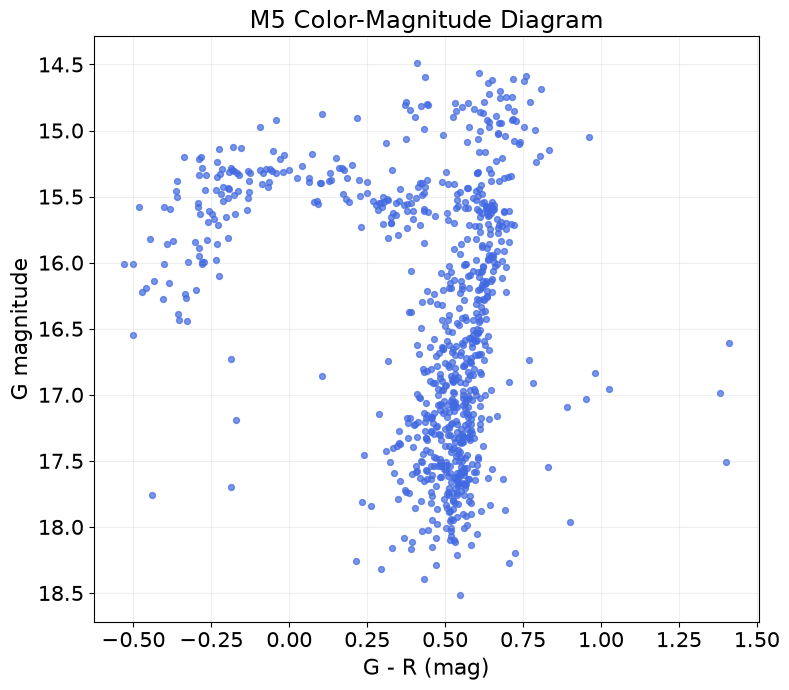

In [28]:
#M5 Color-Magnitude Diagram

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 7))
plt.scatter(color_GR,mag_G,s=18,color="royalblue",alpha=0.7)

plt.xlabel("G - R (mag)", fontsize=16)
plt.ylabel("G magnitude", fontsize=16)
plt.title("M5 Color-Magnitude Diagram", fontsize=17)

# Brighter stars appear at the top
plt.gca().invert_yaxis()

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Why:** We created a color-magnitude diagram using the G and R magnitudes to study the distribution of stars in M5.

**What we found:** We measured 824 matched sources. The CMD shows a concentration of stars around G-R = 0.5–0.7 and a brighter group extending toward bluer colors. Some stars are scattered away from these structures.

In [29]:
# check the color distribution of M5

print("Total sources:",len(color_GR))

print("Minimum G-R color:",np.min(color_GR))
print("Maximum G-R color:", np.max(color_GR))

print("Sources with G-R < -0.5:",np.sum(color_GR < -0.5))

print("Sources with G-R > 2.0:", np.sum(color_GR > 2.0))

Total sources: 824
Minimum G-R color: -0.5305614436361274
Maximum G-R color: 1.4101206209122559
Sources with G-R < -0.5: 2
Sources with G-R > 2.0: 0


In [30]:
# Check if any R-band stars were matched more than once

matched_R =idx[matchflag]

print("Total matches:", len(matched_R))
print("Unique R-band stars:", len(np.unique(matched_R)))

print("Duplicate matches:",len(matched_R) - len(np.unique(matched_R)))

Total matches: 824
Unique R-band stars: 824
Duplicate matches: 0


Mean separation: 0.03619956503859713
Median separation: 0.026749498798678474
Maximum separation: 0.38445601429510556


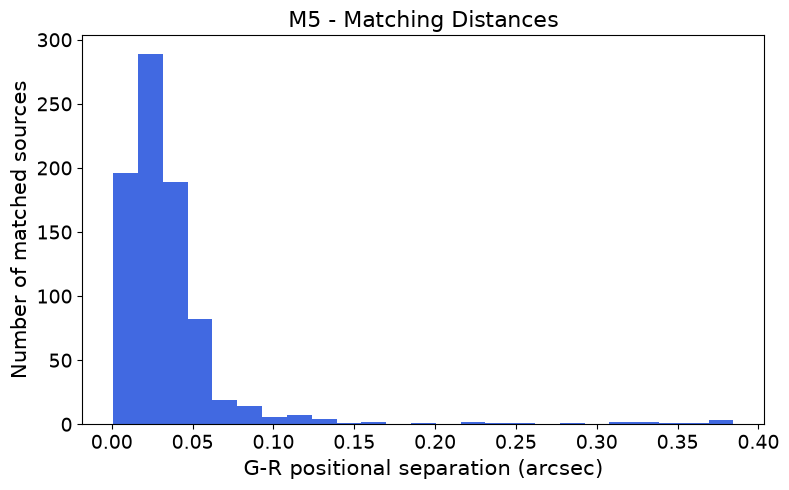

In [31]:
# Check the distance between matched stars

matched_distances = d2d[matchflag].arcsec

print("Mean separation:", np.mean(matched_distances))
print("Median separation:", np.median(matched_distances))
print("Maximum separation:", np.max(matched_distances))

plt.figure(figsize=(8, 5))

plt.hist(matched_distances,bins=25,color="royalblue")

plt.xlabel("G-R positional separation (arcsec)",fontsize=15)
plt.ylabel("Number of matched sources",fontsize=15)
plt.title("M5 - Matching Distances",fontsize=16)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()

**Why:** We plotted the matching distances to check how closely the G-band and R-band source positions agree.

**What we found:** Most sources have very small separations. We found that 794 out of 824 matches have separations smaller than 0.1 arcseconds. There were no duplicate matches, which suggests that the matching was generally good.

In [32]:
#check the quality of the matching

print("Matches below 0.1 arcsec:",np.sum(matched_distances < 0.1))

print("Matches between 0.1 and 0.2 arcsec:",np.sum((matched_distances >= 0.1) &(matched_distances < 0.2)))

print("Matches above 0.2 arcsec:",np.sum(matched_distances >= 0.2))

Matches below 0.1 arcsec: 794
Matches between 0.1 and 0.2 arcsec: 16
Matches above 0.2 arcsec: 14


### Matching Quality

We matched 824 sources between the G and R images of M5.

We found no duplicate matches. Most sources (794 out of 824)
have a separation smaller than 0.1 arcseconds.

Only 14 sources have separations larger than 0.2 arcseconds.

These results suggest that the matching is generally good,
although some sources may still be incorrectly matched.

In [33]:

# M5 - Final quality check
#select sources with small matching distances
good_match = matched_distances < 0.1

#select sources with reasonable preliminary errors
good_error = sigma_color < 0.05

#keep sources that pass both conditions
good_M5 = good_match &good_error

print("Original sources:", len(color_GR))
print("Good matches:", np.sum(good_match))
print("Small color errors:", np.sum(good_error))
print("Sources after both checks:", np.sum(good_M5))
print("Excluded sources:", np.sum(~good_M5))


Original sources: 824
Good matches: 794
Small color errors: 824
Sources after both checks: 794
Excluded sources: 30


### Final Source Selection

We initially measured 824 sources in M5.

To improve the quality of our CMD, we selected sources with a matching distance smaller than 0.1 arcseconds and a color uncertainty smaller than 0.05 magnitudes.

All 824 sources passed the color uncertainty criterion, but only 794 passed the matching distance criterion.

Our final sample contains 794 sources. We excluded 30 sources to reduce the possibility of incorrect matches between the G and R images.

The uncertainty criterion is based on our preliminary sky-noise model and does not include all sources of photometric error.

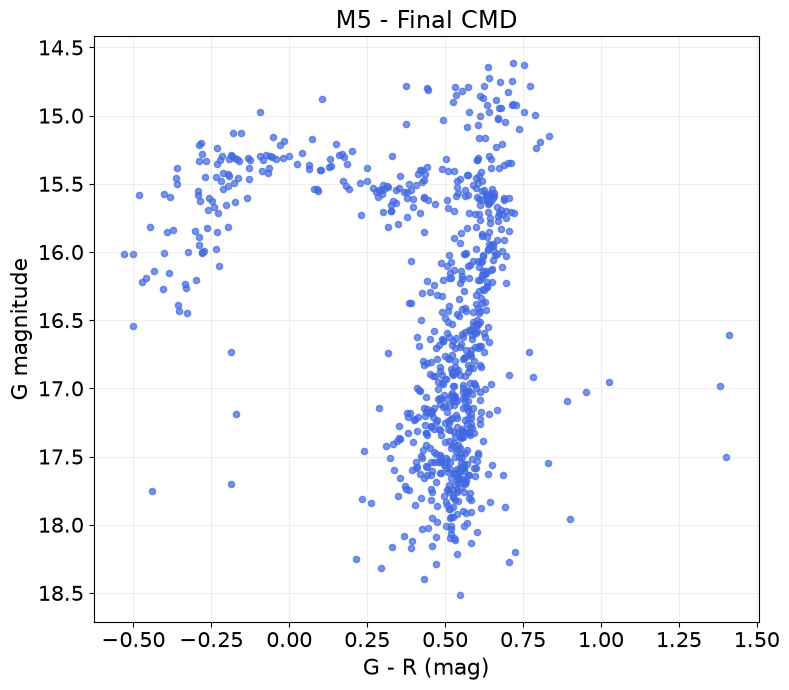

In [34]:
# Final M5 CMD with selected stars

plt.figure(figsize=(8, 7))

plt.scatter(color_GR[good_M5], mag_G[good_M5],s=20, color="royalblue", alpha=0.7)

plt.xlabel("G - R (mag)",fontsize=16)
plt.ylabel("G magnitude",fontsize=16)
plt.title("M5 - Final CMD",fontsize=17)

plt.gca().invert_yaxis()

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Why:** We created a second CMD using sources with matching distances smaller than 0.1 arcseconds and preliminary color uncertainties smaller than 0.05 magnitudes. This helped us check whether less precise matches were affecting the diagram.

**What we found:** We selected 794 sources and excluded 30. The main structure of the CMD remained similar to the original diagram. The mean G-R color is 0.434 magnitudes, and the median is 0.526 magnitudes. The G magnitudes range from 14.614 to 18.515.

### M5 CMD Results

The initial CMD contained 824 sources. After applying a stricter matching distance of 0.1 arcseconds, 794 sources remained.

The final CMD shows a concentration of stars around G-R = 0.5–0.7, extending from approximately G = 15 to G = 18. Another group of brighter stars extends toward bluer colors.

The general shape of the CMD did not change significantly after removing 30 sources. This suggests that the main structures are not caused only by the less precise positional matches.

Some sources are scattered away from the main structures. These may be field stars, overlapping sources, or uncertain photometric measurements.

The CMD provides information about the stellar populations in M5, but additional analysis would be needed to identify specific evolutionary sequences with confidence.

In [35]:
print("Final sources:", np.sum(good_M5))
print("Mean G-R:", np.mean(color_GR[good_M5]))
print("Median G-R:", np.median(color_GR[good_M5]))
print("Brightest G:", np.min(mag_G[good_M5]))
print("Faintest G:", np.max(mag_G[good_M5]))

Final sources: 794
Mean G-R: 0.43353372017352687
Median G-R: 0.5256546087270575
Brightest G: 14.613713347753151
Faintest G: 18.514813178335537


### M5 Conclusion

In this analysis, we used G and R images to study the stellar population of the globular cluster M5.

We initially matched 824 sources between the two filters. After applying a stricter matching distance, we selected 794 sources for our final color-magnitude diagram.

The final sample has a mean G-R color of 0.434 magnitudes and a median color of 0.526 magnitudes. The G magnitudes range from 14.614 to 18.515.

The CMD shows a concentration of stars around G-R = 0.5–0.7 and a brighter group extending toward bluer colors. The overall structure remained similar after removing 30 less precise matches.

These results suggest that the CMD contains different stellar populations, although we cannot identify specific evolutionary stages with certainty from these measurements alone.

Our analysis has several limitations. Some detected sources may be field stars rather than cluster members. Crowding and nearby stars may also affect our aperture photometry, especially the sky background measurements.

In addition, our estimated uncertainties mainly include sky background noise and may underestimate the true photometric errors.

Overall, we successfully measured stellar fluxes, calculated magnitudes and colors, and constructed a CMD for the outer regions of M5. This diagram will be used to compare M5 with the open cluster M67.